# 06 – Error analysis (task 24)

**Question:** where does our model go wrong? We already have one prediction per building from task 20, made by a
model that never saw that building (out-of-fold). We do not train anything new; we only look at the errors.

Three parts, houses first (they are what the energy office cares about), all buildings next to them:
1. **Plausibility:** are the predictions sensible at all (no negative values, nothing absurd)?
2. **Errors by group:** construction period, energy group, building class. Is the model too high or too low anywhere?
3. **The office's list:** which houses end up as false alarms in the top 20%, and which problem houses does the list miss?

**Error = prediction − true value.** Positive = the model guessed too high, negative = too low.

Input: `output/tables/task20_oof_predictions.csv` (from `02_estimate.ipynb`, so run that first).
The test set is not used (rule 1).
Output: `output/tables/task24_*.csv` and `output/figures/task24_*.png`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from config import THRESHOLD
from metrics import _top_positions   # the same ranking (and tie-break) as the selection measure

processed = Path("../data/processed")
tables = Path("../output/tables")
figures = Path("../output/figures")
figures.mkdir(parents=True, exist_ok=True)

MODEL = "Linear regression, expert rule on"   # main model of task 20; change here to analyse another one
MIN_N = 20                                     # groups with fewer houses are shown but not interpreted

## 1. Load predictions and building characteristics

In [2]:
oof = pd.read_csv(tables / "task20_oof_predictions.csv")
info = pd.read_csv(processed / "building_clean.csv")[
    ["EGID", "construction_period", "energy_group", "building_class", "heating_system", "floor_area", "dwellings"]]
df = oof.merge(info, on="EGID", how="left", validate="one_to_one")

df["pred"] = df[MODEL]
df["error"] = df["pred"] - df["y"]           # positive = predicted too high
df["abs_error"] = df["error"].abs()

houses = df[df["house"]].copy()
print("Model analysed:", MODEL)
print("Buildings:", len(df), "| houses:", len(houses))
assert df["pred"].notna().all(), "a building has no prediction"

Model analysed: Linear regression, expert rule on
Buildings: 12710 | houses: 1171


## 2. Plausibility: are the predictions sensible?

The heating index of our buildings lies between 50 and 1,500 (cleaning rule). A prediction outside that range,
or a negative one, would be impossible. We also compare the spread: linear models usually predict
**too close to the average** (they "play it safe"), which we check by comparing the standard deviations.

In [ ]:
def describe(d):
    return pd.DataFrame({
        "true value": d["y"].describe(),
        "prediction": d["pred"].describe(),
    }).round(0)

print("Houses")
print(describe(houses).to_string())
print()
print("All buildings")
print(describe(df).to_string())
print()
print("Predictions below 50:", (df["pred"] < 50).sum(), "| below 0:", (df["pred"] < 0).sum(),
      "| above 1,500:", (df["pred"] > 1500).sum())
print("Spread of predictions vs. true values (houses):",
      round(houses["pred"].std()), "vs.", round(houses["y"].std()))

Houses
       true value  prediction
count      1171.0      1171.0
mean        426.0       425.0
std         152.0        69.0
min          74.0       236.0
25%         321.0       383.0
50%         417.0       438.0
75%         514.0       472.0
max        1499.0       583.0

All buildings
       true value  prediction
count     12710.0     12710.0
mean        396.0       396.0
std         126.0        74.0
min          50.0        19.0
25%         319.0       361.0
50%         390.0       407.0
75%         465.0       443.0
max        1499.0       660.0

Predictions below 50: 2 | below 0: 0 | above 1,500: 0
Spread of predictions vs. true values (houses): 69 vs. 152


**Predicted vs. true value, houses.** Every dot is a house. On the diagonal the prediction is perfect.
The dashed lines are the threshold of 450: the top-right box are problem houses the model also sees as high.

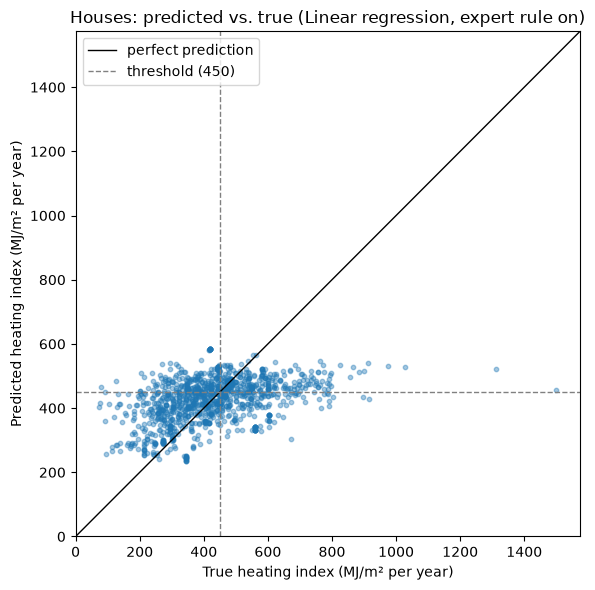

In [3]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(houses["y"], houses["pred"], s=10, alpha=0.4, color="C0")
lims = [0, max(houses["y"].max(), houses["pred"].max()) * 1.05]
ax.plot(lims, lims, color="black", linewidth=1, label="perfect prediction")
ax.axvline(THRESHOLD, color="grey", linestyle="--", linewidth=1, label="threshold (450)")
ax.axhline(THRESHOLD, color="grey", linestyle="--", linewidth=1)
ax.set_xlim(lims)
ax.set_ylim(lims)
ax.set_xlabel("True heating index (MJ/m² per year)")
ax.set_ylabel("Predicted heating index (MJ/m² per year)")
ax.set_title(f"Houses: predicted vs. true ({MODEL})")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(figures / "task24_predicted_vs_true.png", dpi=150)
plt.show()

**Error by true value.** We sort the houses into bands of their true value and look at the mean error in each band.
If the model plays it safe, it guesses too high for good houses (positive bars on the left) and too low for bad
houses (negative bars on the right).

               n  mean_error    mae
true band                          
(0, 250]     115       162.0  162.0
(250, 350]   271        89.3  101.1
(350, 450]   340        35.8   57.5
(450, 550]   224       -43.9   52.5
(550, 700]   164      -164.6  164.8
(700, 1500]   57      -323.6  323.6


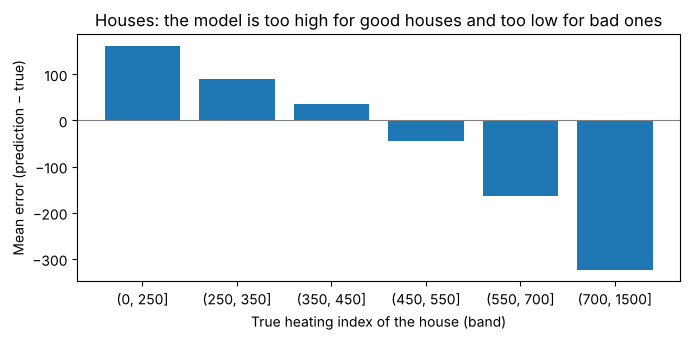

In [ ]:
bands = [0, 250, 350, 450, 550, 700, 1500]
houses["true band"] = pd.cut(houses["y"], bands)
by_band = houses.groupby("true band", observed=True).agg(
    n=("y", "size"), mean_error=("error", "mean"), mae=("abs_error", "mean")).round(1)
print(by_band.to_string())

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(by_band.index.astype(str), by_band["mean_error"], color="C0")
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xlabel("True heating index of the house (band)")
ax.set_ylabel("Mean error (prediction − true)")
ax.set_title("Houses: the model is too high for good houses and too low for bad ones")
fig.tight_layout()
fig.savefig(figures / "task24_error_by_true_value.png", dpi=150)
plt.show()

## 3. Errors by group

One function makes the same table for any characteristic:
- **n:** number of buildings in the group (small groups are noisy, look at n first)
- **mean error:** bias. Clearly above 0 = the model is systematically too high for this group, below 0 = too low
- **MAE:** how far off a typical building is
- **above 450 true / predicted (%):** how often the group really is above 450 vs. how often the model says so

In [ ]:
def error_table(d, by):
    table = d.groupby(by).agg(
        n=("y", "size"),
        mean_true=("y", "mean"),
        mean_pred=("pred", "mean"),
        mean_error=("error", "mean"),
        mae=("abs_error", "mean"),
        above_450_true=("y", lambda s: (s > THRESHOLD).mean() * 100),
        above_450_pred=("pred", lambda s: (s > THRESHOLD).mean() * 100),
    ).round(1)
    table["small group"] = np.where(table["n"] < MIN_N, "yes", "")
    return table

### 3a. Construction period (houses)

Construction periods in the register are in chronological order except "Vor 1919" (before 1919), which we put first.

In [ ]:
period_order = ["Vor 1919", "1919-1945", "1946-1960", "1961-1970", "1971-1980", "1981-1985", "1986-1990",
                "1991-1995", "1996-2000", "2001-2005", "2006-2010", "2011-2015", "Nach 2015", "unknown"]

by_period = error_table(houses, "construction_period")
by_period = by_period.reindex([p for p in period_order if p in by_period.index])
by_period

                       n  mean_true  mean_pred  mean_error    mae  above_450_true  above_450_pred small group
construction_period                                                                                          
Vor 1919             203      450.6      429.6       -21.0  109.0            46.8            34.0            
1919-1945            107      469.6      457.6       -12.0  122.9            51.4            58.9            
1946-1960             74      472.6      501.5        29.0  145.6            41.9            87.8            
1961-1970            107      505.4      478.2       -27.2  133.2            61.7            84.1            
1971-1980            146      468.7      464.7        -4.0   96.7            42.5            70.5            
1981-1985             62      417.5      440.0        22.4  100.6            32.3            43.5            
1986-1990             92      399.1      416.4        17.3   74.3            30.4            22.8            
1991-1995 

### 3b. Energy group (houses)

In [ ]:
by_energy = error_table(houses, "energy_group").sort_values("n", ascending=False)
by_energy

                 n  mean_true  mean_pred  mean_error    mae  above_450_true  above_450_pred small group
energy_group                                                                                           
gas            600      425.1      422.8        -2.3  106.7            41.2            34.8            
oil            380      474.4      473.6        -0.8  108.4            45.3            73.4            
other          108      307.9      329.1        21.2   95.7            10.2             3.7            
heat pump       31      327.9      320.8        -7.0   77.6            19.4             0.0            
wood            23      371.8      372.1         0.3   79.4            21.7             4.3            
district heat   15      415.9      387.1       -28.8  133.5            13.3            13.3         yes
electric        14      347.2      331.2       -16.0   70.1            14.3             0.0         yes


### 3c. Building class (all buildings)

Houses only have two classes (1 or 2 dwellings), so here we look at all buildings. Only classes with at least 50 buildings.

In [ ]:
by_class = error_table(df, "building_class").query("n >= 50").sort_values("n", ascending=False)
by_class

                             n  mean_true  mean_pred  mean_error    mae  above_450_true  above_450_pred small group
building_class                                                                                                     
Gebäude mit 3+ Whgen      9416      395.2      395.3         0.0   62.5            27.9            18.2            
Gebäude mit 1 Wohnung      838      423.1      422.5        -0.6  110.5            37.1            41.5            
Bürogebäude                556      334.6      334.9         0.3   96.5            19.2             4.0            
Gebäude mit 2 Wohnungen    333      432.1      432.8         0.7   90.7            40.2            44.1            
Schul-/Hochschulgebäude    332      339.9      340.1         0.2   98.9            19.6             6.0            
Industriegebäude           287      370.3      371.0         0.7  124.0            26.8            19.2            
Gross- und Einzelhandel    184      378.9      379.1         0.2  118.6 

## 4. The office's list: hits, false alarms and missed houses

The selection measure takes, in each validation fold, the 20% of houses with the highest prediction. These are the
owners the office would contact. Every house falls into one of four boxes:

| | in the top 20% (contacted) | not contacted |
|---|---|---|
| **really above 450** | hit | missed |
| **really below 450** | false alarm | correctly left out |

We rebuild exactly this list (same ranking and tie-break as in `metrics.py`) and ask: what do false alarms and
missed houses look like?

In [ ]:
houses["contacted"] = False
for k in houses["fold"].unique():
    in_fold = houses.index[houses["fold"] == k]                       # houses of validation fold k
    top = _top_positions(houses.loc[in_fold, "pred"].to_numpy(), 0.20)  # the same list as the selection measure
    houses.loc[in_fold[top], "contacted"] = True

above = houses["y"] > THRESHOLD
houses["outcome"] = np.select(
    [houses["contacted"] & above, houses["contacted"] & ~above, ~houses["contacted"] & above],
    ["hit", "false alarm", "missed"], default="correctly left out")

counts = houses["outcome"].value_counts()
print(counts.to_string())
print()
print("Share of hits among contacted houses:", round(counts["hit"] / houses["contacted"].sum() * 100, 1), "%",
      "(should be close to 54% from task 20)")

outcome
correctly left out    618
missed                318
hit                   127
false alarm           108

Share of hits among contacted houses: 54.0 % (should be close to 54% from task 20)


**How far off are the false alarms?** A false alarm at 430 is almost a hit; a false alarm at 250 is a real mistake.

In [ ]:
print("True value of false alarms:")
print(houses.loc[houses["outcome"] == "false alarm", "y"].describe().round(0).to_string())
print()
print("False alarms just below the threshold (400–450):",
      ((houses["outcome"] == "false alarm") & (houses["y"] >= 400)).sum(),
      "of", (houses["outcome"] == "false alarm").sum())
print()
print("True and predicted value of missed problem houses:")
print(houses.loc[houses["outcome"] == "missed", ["y", "pred"]].describe().round(0).to_string())

True value of false alarms:
count    108.0
mean     381.0
std       68.0
min      127.0
25%      341.0
50%      408.0
75%      442.0
max      450.0

False alarms just below the threshold (400–450): 56 of 108

True and predicted value of missed problem houses:
            y   pred
count   318.0  318.0
mean    565.0  430.0
std     105.0   43.0
min     451.0  303.0
25%     485.0  407.0
50%     548.0  443.0
75%     602.0  463.0
max    1499.0  485.0


**Which houses are they?** Share of each construction period and energy group within each outcome.
If, for example, almost all false alarms are old oil-heated houses, the model relies too much on that combination.

In [ ]:
def share_by_outcome(column):
    table = pd.crosstab(houses[column], houses["outcome"], normalize="columns").mul(100).round(1)
    return table[["hit", "false alarm", "missed", "correctly left out"]]

outcome_by_period = share_by_outcome("construction_period")
outcome_by_period = outcome_by_period.reindex([p for p in period_order if p in outcome_by_period.index])
print("Construction period (% of each column)")
print(outcome_by_period.to_string())
print()
print("Energy group (% of each column)")
print(share_by_outcome("energy_group").to_string())

Construction period (% of each column)
outcome               hit  false alarm  missed  correctly left out
construction_period                                               
Vor 1919              8.7          7.4    26.4                16.2
1919-1945            11.8          9.3    12.6                 6.8
1946-1960            15.7         25.9     3.5                 2.4
1961-1970            26.0         16.7    10.4                 3.7
1971-1980            28.3         34.3     8.2                 7.6
1981-1985             2.4          2.8     5.3                 6.3
1986-1990             3.9          0.0     7.2                10.4
1991-1995             3.1          0.9     8.2                 6.5
1996-2000             0.0          0.9     3.8                 7.8
2001-2005             0.0          1.9     3.1                 7.1
2006-2010             0.0          0.0    11.0                11.2
2011-2015             0.0          0.0     0.0                 2.6
Nach 2015             0

## 5. The largest errors

The 10 houses with the largest error in each direction. Do they look like data errors (e.g. a very small floor area,
an implausible value) or like real but unusual houses?

In [ ]:
show_cols = ["EGID", "y", "pred", "error", "construction_period", "energy_group", "heating_system", "floor_area", "dwellings"]
print("Predicted much too LOW (problem houses the model does not see):")
print(houses.nsmallest(10, "error")[show_cols].round(0).to_string(index=False))
print()
print("Predicted much too HIGH:")
print(houses.nlargest(10, "error")[show_cols].round(0).to_string(index=False))

Predicted much too LOW (problem houses the model does not see):
   EGID      y  pred   error construction_period  energy_group                      heating_system  floor_area  dwellings
1029983 1499.0 457.0 -1042.0           1919-1945 district heat          Wärmetauscher für ein Geb.        83.0        1.0
1028849 1311.0 523.0  -788.0           1961-1970           gas       Heizkessel kond. für ein Geb.        97.0        1.0
1022667 1027.0 527.0  -500.0           1971-1980           oil     Heizkessel (gene.) für ein Geb.        83.0        1.0
1012218  916.0 430.0  -486.0            Vor 1919           gas Heizkessel nicht kond. für ein Geb.       178.0        1.0
1004603  898.0 435.0  -463.0           1981-1985           oil     Heizkessel (gene.) für ein Geb.       353.0        1.0
1005812  975.0 530.0  -445.0           1946-1960           oil    Heizkessel (gen.) für mehr. Geb.        69.0        1.0
1007326  791.0 406.0  -385.0           1961-1970           gas     Heizkessel (gen

## 6. Save

In [ ]:
by_period.to_csv(tables / "task24_errors_by_period_houses.csv")
by_energy.to_csv(tables / "task24_errors_by_energy_houses.csv")
by_class.to_csv(tables / "task24_errors_by_class_all.csv")
by_band.to_csv(tables / "task24_errors_by_true_value_houses.csv")
houses[["EGID", "fold", "y", "pred", "error", "contacted", "outcome"]].to_csv(tables / "task24_house_outcomes.csv", index=False)
print("Saved the task24 tables and figures")

Saved the task24 tables and figures


## 7. What we found

*Draft, check against the numbers above before using it in the report.*

- **Plausible:** no negative predictions and none above 1,500. For houses the predictions lie between about 240 and
  580, while the true values go from 74 to 1,499.
- **The model plays it safe.** The predictions spread only half as much as the true values (SD 69 vs. 152). Good houses
  are predicted far too high (+162 below 250) and very bad houses far too low (−324 above 700). Around the threshold
  (350–550) the errors are small (MAE ≈ 55). This explains the large MAE (~105) while the ranking still works:
  the order is mostly right, the extremes are pulled towards the middle.
- **The list is driven by oil heating.** Only about a third of houses heat with oil, but oil houses make up 68% of the
  hits and 74% of the false alarms. The model in effect says "old and oil-heated → contact".
- **The model misses problem houses heated with gas.** 65% of the missed problem houses use gas, and 26% were built before 1919. The model
  predicts pre-1919 houses too low (34% predicted above 450 vs. 47% truly above).
- **Over-flagged periods:** 1946–1980 houses are predicted above 450 far more often than they are (e.g. 1946–1960:
  88% predicted vs. 42% true). Houses from 2006–2010 are never predicted above 450, although 34% are.
- **Many false alarms are near misses.** 56 of 108 false alarms are between 400 and 450; their median is 408.
  For the office, these owners are close to the threshold anyway.
- **Missed houses sit just below the cut.** Their median prediction is 443 vs. a true median of 548.
- **Houses are harder than other buildings.** MAE ≈ 110 for one-dwelling houses vs. ≈ 63 for apartment blocks
  (the mean error by class is ~0 because the class is a feature, so the model learns each class's average).
- **Largest errors** look like what the register cannot see: values of 1,300–1,500 in small houses (80–100 m²), which may
  be floor-area errors in the heating file, and values below 150 in old houses, probably renovations. The register has no
  information on renovations: a limitation for the report.